# Imports 

In [1]:
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from skopt import BayesSearchCV
from sklearn.metrics import confusion_matrix
import joblib
from sklvq import GLVQ
import matplotlib.pyplot as plt
from sklearn.ensemble import AdaBoostClassifier

random_state=42

-----

# Functions

In [2]:
def train_validation_test_split(
        X, y, validation_size=0.1,
        test_size=0.1, random_state=42):
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )

    X_train, X_valid, y_train, y_valid = train_test_split(
        X_train, y_train,
        test_size=validation_size / (1 - test_size),
        random_state=random_state,
        stratify=y_train,
    )
    return X_train, X_valid, X_test, y_train, y_valid, y_test

In [67]:
from scipy import stats
def confidence_interval(data, confidence=0.95):
    mean = np.mean(data)
    n = len(data)
    std_err = np.std(data, ddof=1) / np.sqrt(n)
    t_value = stats.t.ppf((1 + confidence) / 2, n - 1)
    margin_of_error = t_value * std_err

    return f"{mean:.5f} ± {margin_of_error:.5f}"

In [64]:
def report_model_performance(model, X_train, X_valid, X_test, y_train, y_valid, y_test):
    
    accuracy_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_Accuracy"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    precision_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_Precision"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    recall_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_Recall"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    f1_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_F1"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    roc_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_ROC-AUC"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]

    best_param = model.steps[-1][-1].best_params_
    print(f"Best parameters: {best_param}")
    print(f"Cross Validation accuracy Array: {accuracy_best_param_cv}")
    print(f"Validation accuracy: {confidence_interval(accuracy_best_param_cv)}")
    
    print(f"Cross Validation precision Array: {precision_best_param_cv}")
    print(f"Validation precision: {confidence_interval(precision_best_param_cv)}")
    
    print(f"Cross Validation recall Array: {recall_best_param_cv}")
    print(f"Validation recall: {confidence_interval(recall_best_param_cv)}")
    
    print(f"Cross Validation f1 Array: {f1_best_param_cv}")
    print(f"Validation f1: {confidence_interval(f1_best_param_cv)}")
    
    print(f"Cross Validation roc Array: {roc_best_param_cv}")
    print(f"Validation roc: {confidence_interval(roc_best_param_cv)}")
    
    print()
    y_train_pred = model.predict(X_train)
    y_valid_pred = model.predict(X_valid)
    y_test_pred = model.predict(X_test)
    
    y_train_proba = model.predict_proba(X_train)
    y_valid_proba = model.predict_proba(X_valid)
    y_test_proba = model.predict_proba(X_test)
    print("===> Training performance")
    print(classification_report(y_train, y_train_pred, digits=5))
    print(f"Train ROC-AUC: {roc_auc_score(y_train, y_train_proba, multi_class='ovr'):.3f}")
    print("===> Validation performance")
    print(classification_report(y_valid, y_valid_pred, digits=5))
    print(f"Validation ROC-AUC: {roc_auc_score(y_valid, y_valid_proba, multi_class='ovr'):.3f}")
    print("===> Test performance")
    print(classification_report(y_test, y_test_pred, digits=5))
    print(f"Test ROC-AUC: {roc_auc_score(y_test, y_test_proba, multi_class='ovr'):.3f}")
    
    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_train, y_train_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Train Confusion Matrix")
        plt.show()

    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_valid, y_valid_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Validation Confusion Matrix")
        plt.show()
        
    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_test, y_test_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Test Confusion Matrix")
        plt.show()

In [24]:
def save_model(model, model_name):
    joblib.dump(model, f"{model_name}.joblib")

# Read Dataset

In [5]:
iris = fetch_ucirepo(id=53)

X = iris.data.features
y = iris.data.targets

# Descritive statistics

In [6]:
X.describe()

,sepal length,sepal width,petal length,petal width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [7]:
y["class"].value_counts(normalize=True)

class
Iris-setosa        0.333333
Iris-versicolor    0.333333
Iris-virginica     0.333333
Name: proportion, dtype: float64

<Axes: >

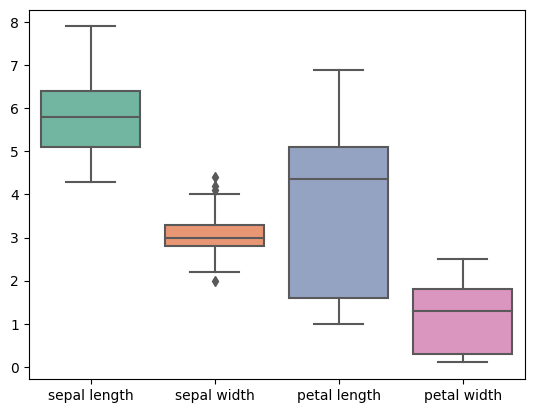

In [8]:
sns.boxplot(X, palette="Set2")

## Split Dataset

In [11]:
X_train, X_valid, X_test, y_train, y_valid, y_test = train_validation_test_split(
    X, y, validation_size=0.15, test_size=0.15, random_state=random_state
)

In [12]:
X_train.shape, X_valid.shape, X_test.shape

((104, 4), (23, 4), (23, 4))

# Pre-processing

## Scaling the data

In [13]:
scaler_knn = MinMaxScaler()
scaler_lvq = MinMaxScaler()
scaler_dt = MinMaxScaler()
scaler_rf = MinMaxScaler()
scaler_ada = MinMaxScaler()
scaler_mlp = MinMaxScaler()

# Model

## KNN 

In [49]:
cv = StratifiedShuffleSplit(n_splits=100, test_size=0.2, random_state=random_state)
knn = KNeighborsClassifier()

scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
knn_opt = BayesSearchCV(
    knn,
    {
        "n_neighbors": (1, 80),
        "weights": ["uniform", "distance"],
        "p": (1, 2, 3, 4, 5),
    },
    n_iter=50,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_knn = Pipeline([("scaler", scaler_knn), ("knn", knn_opt)])

In [50]:
pipe_knn.fit(X_train, y_train["class"])

Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 1

/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [53, 1, 'distance'] before, using random point [7, 2, 'distance']
  warnings.warn(


Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 1

/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/e

Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits


Pipeline(steps=[('scaler', MinMaxScaler()),
                ('knn',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=100, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=KNeighborsClassifier(), n_jobs=-1,
                               random_state=42, refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'n_neighbors': (1, 80),
                                              'p': (1, 2, 3, 4, 5),
                                              'weights': ['uniform',
                                                          'distance']},
                               verbose=1))])

Best parameters: OrderedDict([('n_neighbors', 71), ('p', 5), ('weights', 'distance')])
Cross Validation accuracy Array: [1.         0.95238095 1.         1.         0.95238095 0.95238095
 1.         0.95238095 0.95238095 0.9047619  0.95238095 1.
 0.95238095 1.         0.9047619  0.95238095 1.         1.
 1.         1.         1.         0.9047619  0.95238095 0.9047619
 0.95238095 1.         1.         0.95238095 0.9047619  0.9047619
 0.95238095 1.         1.         0.85714286 0.95238095 1.
 1.         1.         0.85714286 0.95238095 0.95238095 1.
 1.         0.95238095 1.         1.         1.         0.95238095
 0.9047619  0.9047619  1.         0.95238095 1.         1.
 0.95238095 0.9047619  0.95238095 1.         0.95238095 0.95238095
 0.9047619  0.95238095 0.80952381 0.95238095 0.95238095 0.95238095
 0.85714286 0.95238095 1.         0.95238095 0.95238095 0.95238095
 0.95238095 1.         1.         0.95238095 1.         0.95238095
 0.95238095 0.95238095 0.95238095 1.         0.9523

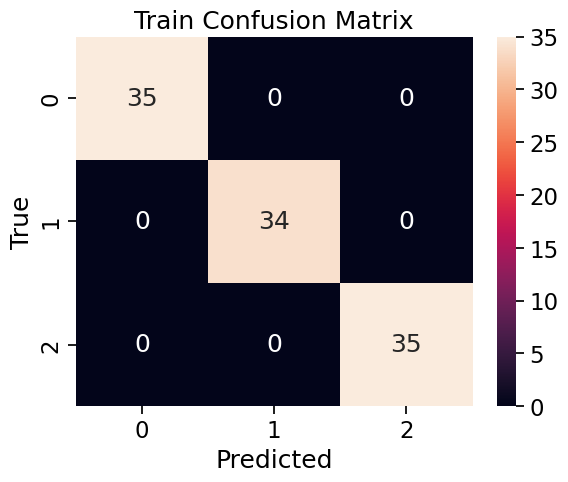

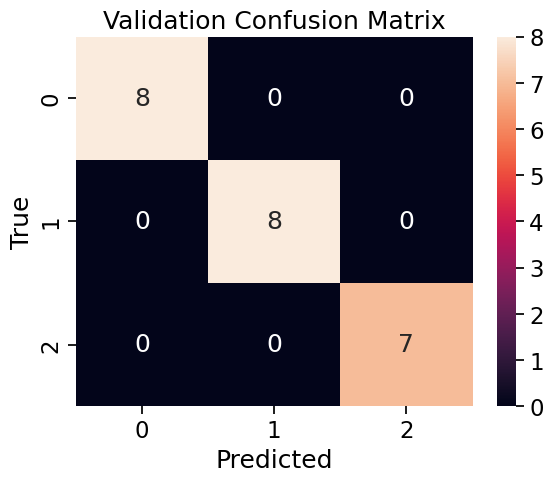

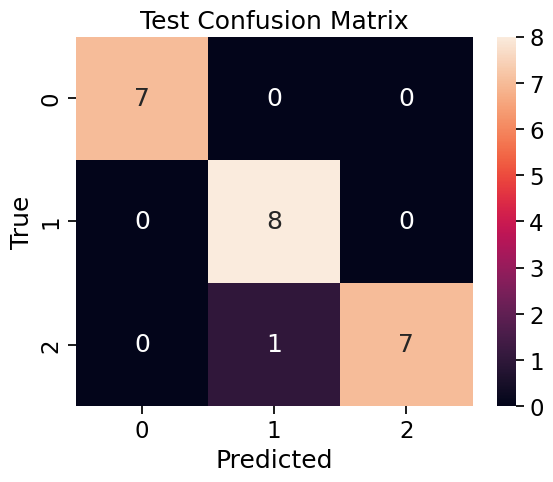

In [68]:
report_model_performance(pipe_knn, X_train, X_valid, X_test, y_train["class"], y_valid["class"], y_test["class"])

In [37]:
save_model(pipe_knn, "knn")

## LVQ

In [72]:
from skopt.space import Integer, Categorical

cv = StratifiedShuffleSplit(n_splits=100, test_size=0.2, random_state=random_state)
lvq = GLVQ(random_state=random_state)
lvq_opt = BayesSearchCV(
    lvq,
    {
        "prototype_n_per_class": (1,100),
        "distance_type": ["euclidean", "squared-euclidean"],
    },
    n_iter=32,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_lvq = Pipeline([("scaler", scaler_lvq), ("lvq", lvq_opt)])

In [73]:
pipe_lvq.fit(X_train, y_train["class"])

Fitting 100 folds for each of 1 candidates, totalling 100 fits


Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 1

Pipeline(steps=[('scaler', MinMaxScaler()),
                ('lvq',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=100, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=GLVQ(random_state=42), n_iter=32,
                               n_jobs=-1, random_state=42, refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'distance_type': ['euclidean',
                                                                'squared-euclidean'],
                                              'prototype_n_per_class': (1,
                                                                        100)},
                               verbose=1))])

Best parameters: OrderedDict([('distance_type', 'euclidean'), ('prototype_n_per_class', 40)])
Cross Validation accuracy Array: [1.         0.95238095 1.         1.         1.         0.95238095
 1.         0.95238095 0.95238095 0.9047619  0.95238095 1.
 0.9047619  0.95238095 0.9047619  0.95238095 0.95238095 1.
 1.         1.         1.         0.9047619  1.         0.9047619
 0.95238095 1.         1.         0.95238095 0.95238095 0.9047619
 0.95238095 1.         1.         0.9047619  0.95238095 1.
 1.         1.         0.85714286 0.95238095 0.9047619  1.
 1.         0.95238095 1.         1.         1.         0.95238095
 0.9047619  0.9047619  1.         0.95238095 1.         1.
 0.95238095 0.95238095 0.95238095 1.         0.95238095 0.9047619
 0.9047619  0.95238095 0.85714286 1.         0.95238095 0.95238095
 0.9047619  0.95238095 1.         0.95238095 0.95238095 0.95238095
 0.95238095 1.         1.         0.95238095 1.         0.95238095
 0.9047619  1.         1.         1.         

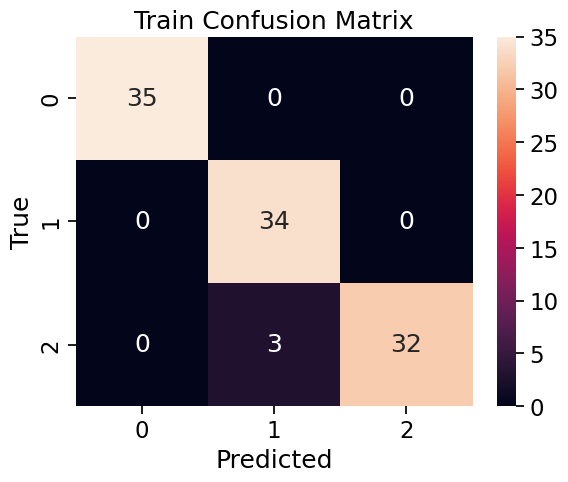

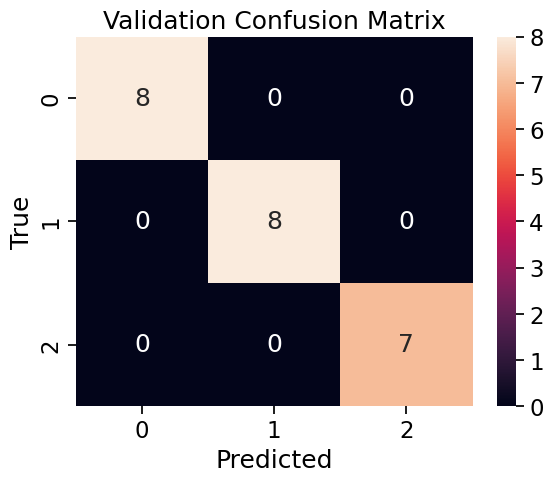

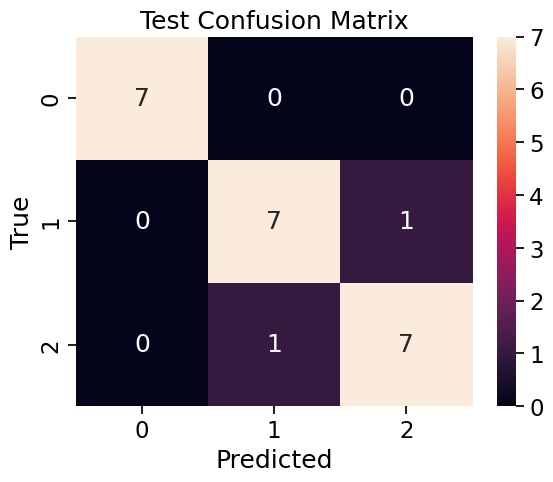

In [74]:
report_model_performance(pipe_lvq, X_train, X_valid, X_test, y_train["class"], y_valid["class"], y_test["class"])

In [75]:
save_model(pipe_lvq, "lvq")

## Decision Tree 

In [76]:
cv = StratifiedShuffleSplit(n_splits=100, test_size=0.2, random_state=random_state)
dt = DecisionTreeClassifier(random_state=random_state)
dt_opt = BayesSearchCV(
    dt,
    {
        "criterion": ["gini", "entropy"],
        "splitter": ["best", "random"],
        "max_depth": (1, 100),
        "min_samples_split": (2, 100),
        "min_samples_leaf": (1, 100),
    },
    n_iter=50,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_dt = Pipeline([("scaler", scaler_dt), ("dt", dt_opt)])

In [77]:
pipe_dt.fit(X_train, y_train["class"])

Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits


/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/e

Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits


/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/e

Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits


/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/e

... (12 outputs left out)

Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits


/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/e

Fitting 100 folds for each of 1 candidates, totalling 100 fits


Pipeline(steps=[('scaler', MinMaxScaler()),
                ('dt',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=100, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=DecisionTreeClassifier(random_state=42),
                               n_jobs=-1, random_state=42, refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'criterion': ['gini', 'entropy'],
                                              'max_depth': (1, 100),
                                              'min_samples_leaf': (1, 100),
                                              'min_samples_split': (2, 100),
                                              'splitter': ['best', 'random']},
                               verbose=1))])

In [78]:
save_model(pipe_dt, "dt")

Best parameters: OrderedDict([('criterion', 'gini'), ('max_depth', 100), ('min_samples_leaf', 7), ('min_samples_split', 33), ('splitter', 'random')])
Cross Validation accuracy Array: [1.         0.9047619  1.         1.         0.80952381 0.95238095
 1.         0.9047619  0.9047619  0.95238095 0.95238095 1.
 0.9047619  0.9047619  0.95238095 0.95238095 0.95238095 0.95238095
 1.         1.         0.95238095 0.95238095 0.9047619  0.95238095
 0.95238095 0.9047619  1.         0.95238095 0.85714286 0.9047619
 0.9047619  1.         1.         1.         0.9047619  0.95238095
 0.95238095 0.9047619  0.9047619  0.9047619  0.9047619  0.95238095
 1.         0.95238095 1.         1.         0.95238095 1.
 0.95238095 0.9047619  1.         1.         1.         1.
 0.85714286 1.         0.85714286 0.95238095 0.95238095 0.95238095
 0.95238095 0.95238095 0.95238095 0.9047619  0.95238095 0.95238095
 0.9047619  1.         0.95238095 0.95238095 0.95238095 1.
 0.95238095 1.         0.95238095 1.         1

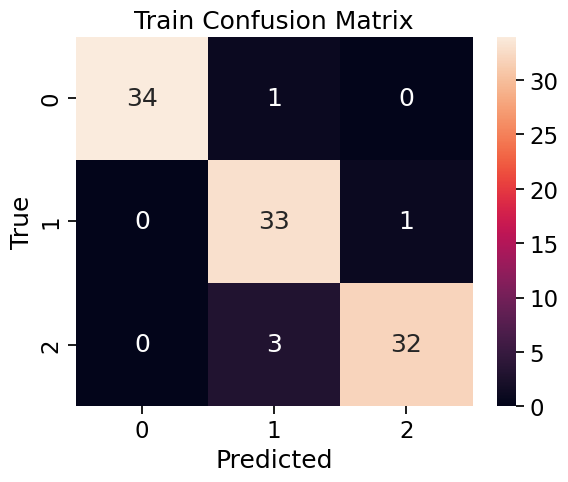

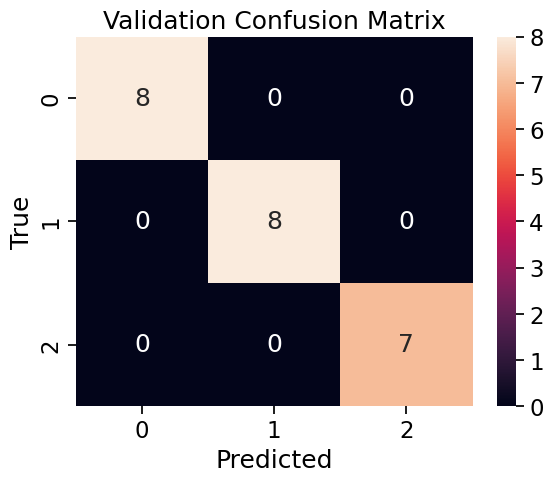

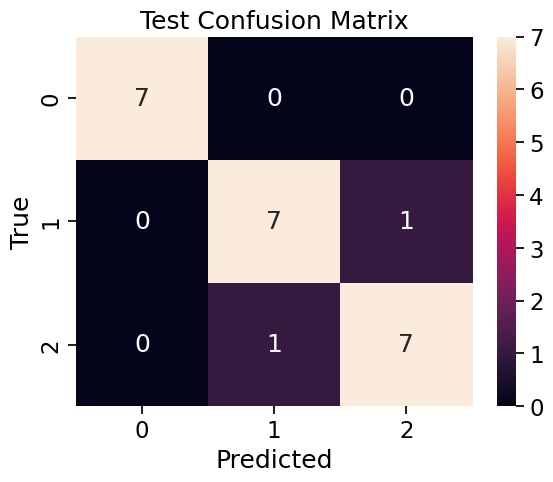

In [79]:
report_model_performance(pipe_dt, X_train, X_valid, X_test, y_train["class"], y_valid["class"], y_test["class"])

## Random Forest

In [80]:
cv = StratifiedShuffleSplit(n_splits=100, test_size=0.2, random_state=random_state)
rf = RandomForestClassifier(random_state=random_state)
rf_opt = BayesSearchCV(
    rf,
    {
        "n_estimators": (1, 1000),
        "criterion": ["gini", "entropy"],
        "max_depth": (1, 100),
        "min_samples_split": (2, 100),
        "min_samples_leaf": (1, 100),
        "max_features": Categorical([None, "sqrt", "log2"]),
    },
    n_iter=50,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_rf = Pipeline([("scaler", scaler_rf), ("rfr", rf_opt)])

In [81]:
pipe_rf.fit(X_train, y_train["class"])

Fitting 100 folds for each of 1 candidates, totalling 100 fits


/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/e

Fitting 100 folds for each of 1 candidates, totalling 100 fits


/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/e

Fitting 100 folds for each of 1 candidates, totalling 100 fits


/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/e

... (52 outputs left out)

Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits


/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/e

Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits


Pipeline(steps=[('scaler', MinMaxScaler()),
                ('rfr',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=100, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=RandomForestClassifier(random_state=42),
                               n_jobs=-1, random_state=42, refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'criterion': ['gini', 'entropy'],
                                              'max_depth': (1, 100),
                                              'max_features': Categorical(categories=(None, 'sqrt', 'log2'), prior=None),
                                              'min_samples_leaf': (1, 100),
                                              'min_samples_split': (2, 100),
                                              'n_estimators': (1, 1000)},
                               verbose=1))])

In [ ]:
X.sample(frac=1, random_state=random_state).reset_index(drop=True)

In [82]:
save_model(pipe_rf, "rf")

Best parameters: OrderedDict([('criterion', 'entropy'), ('max_depth', 88), ('max_features', 'log2'), ('min_samples_leaf', 1), ('min_samples_split', 4), ('n_estimators', 909)])
Cross Validation accuracy Array: [0.9047619  0.95238095 0.95238095 0.95238095 0.9047619  0.95238095
 0.95238095 0.95238095 0.95238095 0.9047619  0.95238095 1.
 0.95238095 0.95238095 0.95238095 0.95238095 0.95238095 1.
 1.         1.         1.         0.9047619  0.95238095 0.9047619
 0.95238095 0.95238095 0.95238095 0.95238095 0.95238095 0.85714286
 0.95238095 1.         1.         1.         0.95238095 1.
 0.9047619  0.85714286 0.85714286 0.95238095 0.9047619  1.
 1.         1.         0.85714286 0.9047619  1.         0.95238095
 1.         0.9047619  1.         0.95238095 0.95238095 0.85714286
 0.95238095 1.         0.9047619  1.         0.95238095 0.95238095
 0.95238095 0.9047619  0.9047619  0.95238095 0.95238095 0.95238095
 0.9047619  0.95238095 1.         0.95238095 0.95238095 0.95238095
 1.         1.      

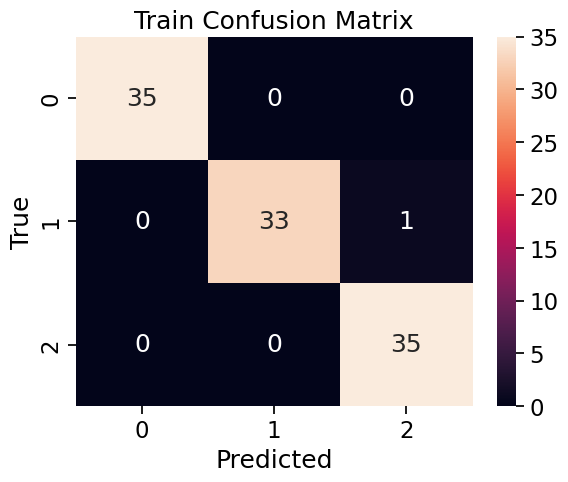

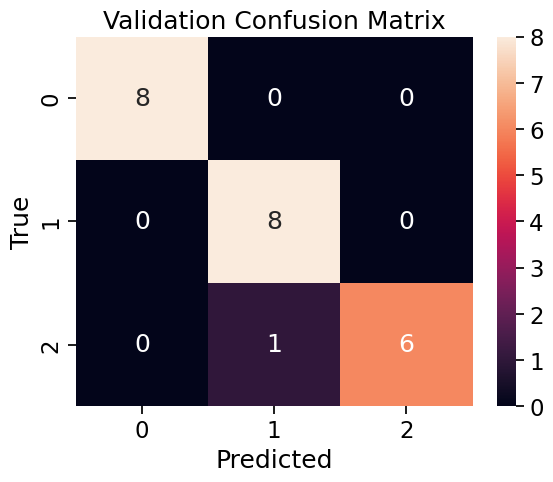

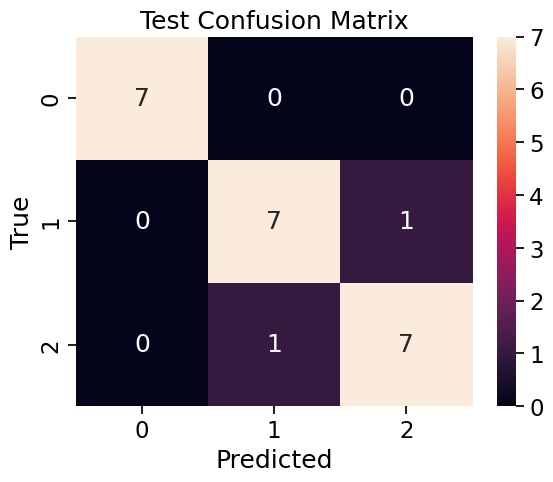

In [83]:
report_model_performance(pipe_rf, X_train, X_valid, X_test, y_train["class"], y_valid["class"], y_test["class"])

## AdaBoost

In [84]:
cv = StratifiedShuffleSplit(n_splits=100, test_size=0.2, random_state=random_state)
ada = AdaBoostClassifier(random_state=random_state)
ada_opt = BayesSearchCV(
    ada,
    {
        "n_estimators": (1, 1000),
        "learning_rate": (0.01, 1),
        "algorithm": ["SAMME", "SAMME.R"],
    },
    n_iter=50,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_opt = Pipeline([("scaler", scaler_ada), ("ada", ada_opt)])

In [85]:
pipe_opt.fit(X_train, y_train["class"])

Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits


/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/e

Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits


/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/e

Fitting 100 folds for each of 1 candidates, totalling 100 fits


/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/e

... (30 outputs left out)

Fitting 100 folds for each of 1 candidates, totalling 100 fits


/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/e

Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits


Pipeline(steps=[('scaler', MinMaxScaler()),
                ('ada',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=100, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=AdaBoostClassifier(random_state=42),
                               n_jobs=-1, random_state=42, refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'algorithm': ['SAMME', 'SAMME.R'],
                                              'learning_rate': (0.01, 1),
                                              'n_estimators': (1, 1000)},
                               verbose=1))])

In [86]:
save_model(pipe_opt, "ada")

Best parameters: OrderedDict([('algorithm', 'SAMME'), ('learning_rate', 0.010244012366393732), ('n_estimators', 889)])
Cross Validation accuracy Array: [0.9047619  0.95238095 0.95238095 0.95238095 0.85714286 1.
 0.95238095 0.95238095 0.95238095 0.9047619  1.         1.
 0.9047619  0.95238095 0.9047619  0.95238095 0.95238095 1.
 1.         1.         1.         0.95238095 0.95238095 0.9047619
 1.         0.95238095 0.95238095 0.95238095 0.95238095 0.9047619
 0.9047619  1.         1.         1.         0.95238095 1.
 0.9047619  0.85714286 0.9047619  0.9047619  0.9047619  1.
 1.         1.         0.85714286 0.9047619  1.         0.95238095
 1.         0.9047619  1.         0.95238095 0.95238095 0.85714286
 0.95238095 1.         0.95238095 1.         0.95238095 0.95238095
 1.         0.9047619  0.9047619  0.9047619  0.95238095 1.
 0.9047619  0.95238095 1.         1.         1.         0.95238095
 1.         0.9047619  1.         0.85714286 1.         0.9047619
 0.95238095 0.9047619  0.952

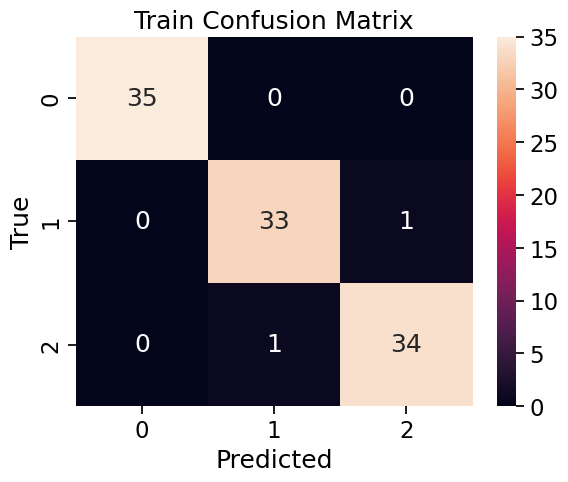

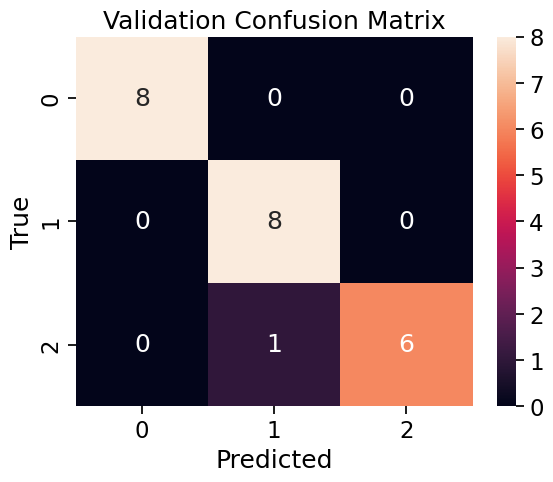

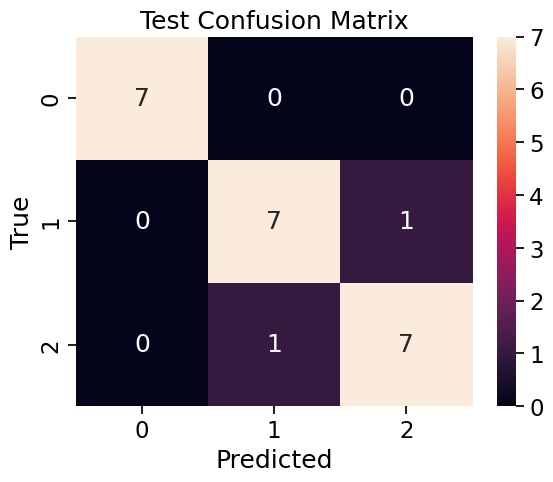

In [87]:
report_model_performance(pipe_opt, X_train, X_valid, X_test, y_train["class"], y_valid["class"], y_test["class"])

## MLP

In [88]:
cv = StratifiedShuffleSplit(n_splits=100, test_size=0.2, random_state=random_state)
mlp = MLPClassifier(random_state=random_state, max_iter=1000)
mlp_opt = RandomizedSearchCV(
    mlp,
    {
        "hidden_layer_sizes": [(5,), (10,), (5, 10), (10, 5), (10, 10)],
        "activation": ["identity", "logistic", "tanh", "relu"],
        "solver": ["lbfgs", "sgd", "adam"],
        "alpha": (1e-5, 1e-1, "log-uniform"),
        "learning_rate": ["constant", "invscaling", "adaptive"],
    },
    n_iter=50,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_mlp = Pipeline([("scaler", scaler_mlp), ("mlp", mlp_opt)])

In [89]:
pipe_mlp.fit(X_train, y_train["class"])

Fitting 100 folds for each of 50 candidates, totalling 5000 fits


/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged ye

Pipeline(steps=[('scaler', MinMaxScaler()),
                ('mlp',
                 RandomizedSearchCV(cv=StratifiedShuffleSplit(n_splits=100, random_state=42, test_size=0.2,
            train_size=None),
                                    estimator=MLPClassifier(max_iter=1000,
                                                            random_state=42),
                                    n_iter=50, n_jobs=-1,
                                    param_distributions={'activation': ['identity',
                                                                        'logistic',
                                                                        'tanh',
                                                                        'relu'],
                                                         'alpha': (1e-05, 0.1,
                                                                   'log-uniform'),
                                                         'hidden_layer_sizes': [(5,),
                                                                                (10,),
                                                                                (5,
                                                                                 10),
                                                                                (10,
                                                                                 5),
                                                                                (10,
                                                                                 10)],
                                                         'learning_rate': ['constant',
                                                                           'invscaling',
                                                                           'adaptive'],
                                                         'solver': ['lbfgs',
                                                                    'sgd',
                                                                    'adam']},
                                    random_state=42, refit='Accuracy',
                                    scoring={'Accuracy': 'accuracy',
                                             'F1': 'f1_macro',
                                             'Precision': 'precision_macro',
                                             'ROC-AUC': 'roc_auc_ovr',
                                             'Recall': 'recall_macro'},
                                    verbose=1))])

Best parameters: {'solver': 'adam', 'learning_rate': 'constant', 'hidden_layer_sizes': (5,), 'alpha': 1e-05, 'activation': 'tanh'}
Cross Validation accuracy Array: [0.95238095 0.95238095 0.95238095 0.9047619  0.9047619  1.
 0.9047619  1.         0.95238095 0.95238095 1.         1.
 0.95238095 0.95238095 0.85714286 0.95238095 0.95238095 1.
 1.         1.         1.         0.95238095 0.95238095 0.9047619
 0.95238095 1.         0.95238095 0.95238095 1.         0.9047619
 1.         1.         0.95238095 1.         0.95238095 1.
 0.95238095 0.9047619  0.85714286 1.         0.95238095 1.
 0.95238095 1.         1.         0.95238095 1.         0.95238095
 1.         1.         0.9047619  0.95238095 0.95238095 0.9047619
 0.85714286 1.         0.95238095 1.         1.         0.9047619
 1.         0.9047619  0.85714286 0.95238095 0.95238095 0.95238095
 1.         0.95238095 1.         1.         1.         0.95238095
 1.         0.95238095 0.95238095 0.9047619  0.95238095 1.
 0.95238095 0.952

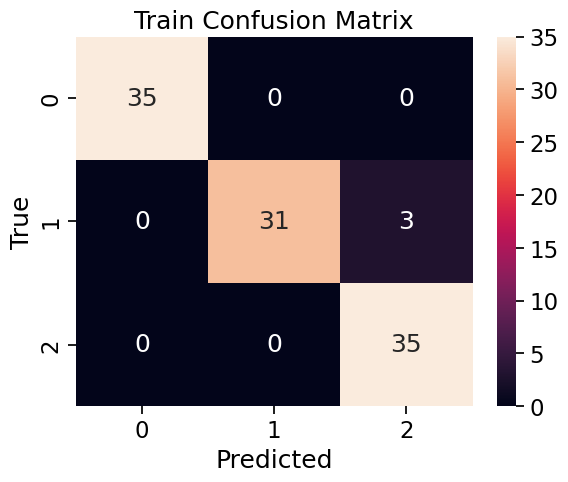

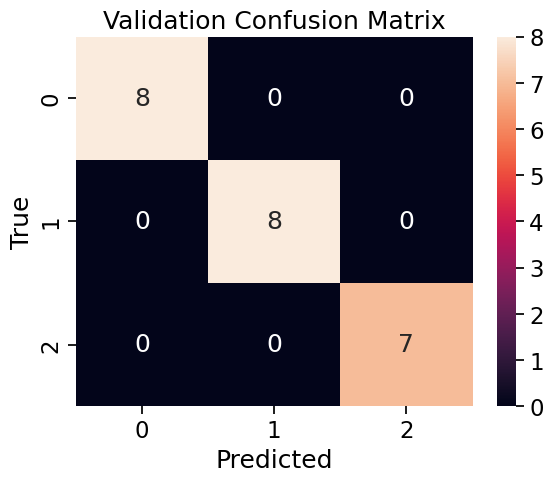

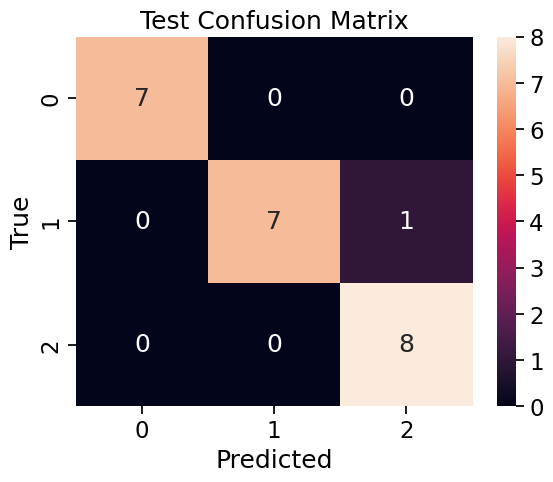

In [90]:
report_model_performance(pipe_mlp, X_train, X_valid, X_test, y_train["class"], y_valid["class"], y_test["class"])

In [91]:
save_model(pipe_mlp, "mlp")

In [92]:
23

23

In [1]:
2

2